## Processing ThermoMute

In [ ]:
import pandas as pd
from Bio import SeqIO

data = {'id': [], 'description': [], 'sequence': [], 'length': []}

with open("../../data/raw/mscramm-filtered.fasta") as handle:
    for rec in SeqIO.parse(handle, "fasta"):
        seq_str = str(rec.seq)
        data['id'].append(rec.id)
        data['description'].append(rec.description)
        data['sequence'].append(seq_str)
        data['length'].append(len(seq_str))

df = pd.DataFrame(data)

In [2]:
df

,id,description,sequence,length
0,WP_436410338.1,WP_436410338.1 segregation and condensation pr...,MLPLDGMQANGYEIKLPQFEGPFDLLLFFIERDELNIHDIPIAKIT...,260
1,XXP61525.1,XXP61525.1 surface glycoprotein [Severe acute ...,MFVFLVLLPLVSSQCVMPLFNLITTTQSYTNFTRGVYYPDKVFRSS...,1268
2,XXP61513.1,XXP61513.1 surface glycoprotein [Severe acute ...,MFVFLVLLPLVSSQCVMPLFNLITTTQSYTNFTRGVYYPDKVFRSS...,1268
3,XXP61501.1,XXP61501.1 surface glycoprotein [Severe acute ...,MFVFLVLLPLVSSQCVMPLFNLITTNQSYTNPFTRGVYYPDKVFRS...,1269
4,XXP61489.1,XXP61489.1 surface glycoprotein [Severe acute ...,MFVFLVLLPLVSSQCVNLITTTQSYTNFTRGVYYPDKVFRSSVLHL...,1264
...,...,...,...,...
3557156,EDS80245.1,EDS80245.1 segregation and condensation protei...,MEMPIIKLKNFDGPFDLLLHLIKKNEMSITEIKIHEITKQYLEYIA...,248
3557157,EDS79533.1,EDS79533.1 putative fibronectin-binding protei...,MKPFIKKEDFNFIKKCITDLHGTLRNCTDPNIIETNKAYINEKILS...,220
3557158,EDS79100.1,EDS79100.1 ferrous iron transport protein A [C...,MKLHEAKILSTVKVIDIKAQGELRRRFFDLGIIEGTDIKVLYAGPF...,72
3557159,EDS78558.1,EDS78558.1 carbon starvation protein A [Clostr...,MVSFILSIIALIVGYVVYGKVVEKCFGANDDIETPATRLEDGVDFV...,478


In [3]:
df.drop_duplicates(subset=['sequence'], inplace=True)   # Remove all duplicate sequences
df = df[df['length'] < 1024]                            # Keep all sequences within context window of 1024 (ESM2)

In [4]:
df

,id,description,sequence,length
0,WP_436410338.1,WP_436410338.1 segregation and condensation pr...,MLPLDGMQANGYEIKLPQFEGPFDLLLFFIERDELNIHDIPIAKIT...,260
19,WP_436408850.1,WP_436408850.1 replication initiator protein A...,MQREQLDLFRALPGDMAPRDSQDLMAFPFFSLAKSRRTAPIDFRAG...,272
20,WP_436408832.1,WP_436408832.1 MSCRAMM family protein [Enteroc...,MLTKIDDQSGEVLQGAVFELQDANGTVLQSGLTTGEDGKLAIDGLA...,327
22,WP_436408679.1,WP_436408679.1 FimV/HubP family polar landmark...,MPLAQAAPSDAAANAPQSITVQPGQSLNDIAVAATQSRDPGVLARA...,773
23,WP_436408533.1,WP_436408533.1 segregation and condensation pr...,MAPSPEPVGETIETAPEPEAQDDSFRVALSNFEGPFDLLLSLISKR...,281
...,...,...,...,...
3557146,EDS90450.1,EDS90450.1 molybdopterin-guanine dinucleotide ...,MNLMTTITGVVLAGGKARRMGGADKGLLELNGKPLWQHVADALMTQ...,194
3557147,CAM58959.1,CAM58959.1 NKG2A protein [Pan troglodytes],MDNQGVIYSDLNLPPNPKRQQRKPKGNKSSILATEQEITYAELNLQ...,233
3557148,ABQ75884.1,ABQ75884.1 molybdopterin-guanine dinucleotide ...,MLFTPGLYYHRMRGGVVLAGGRSTRFGNRDKAVVTLAGTPLIKRVV...,222
3557155,EDS80421.1,EDS80421.1 molybdenum cofactor biosynthesis pr...,MYKEEGEKMKDKYGREIDYLRISLTDKCNLRCAYCMEKDHNDFIHN...,331


In [6]:
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio import SeqIO

# Convert DataFrame rows back into SeqRecord objects
records = []
for _, row in df.iterrows():
    record = SeqRecord(
        Seq(row['sequence']),
        id=row['id'],
        description=row['description']
    )
    records.append(record)

# Write to FASTA file
with open("../../data/processed/cwa-1.5M.fasta", "w") as output_handle:
    SeqIO.write(records, output_handle, "fasta")

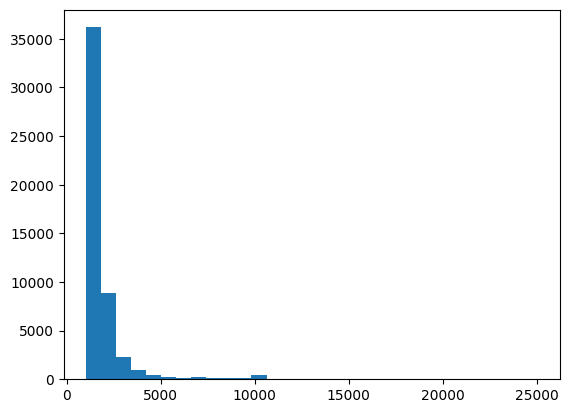

In [18]:
import matplotlib.pyplot as plt

plt.hist(sequences_df['sequence'].apply(lambda s: len(s)), bins=30)
plt.show()

In [20]:
df['sequence'][0]

'MKKRIDYLSNKQNKYSIRRFTVGTTSVIVGATILFGIGNHQAQASEQSNDTTQSSKNNASADSEKNNMIETPQLNTTANDTSDISANTNSANVDSTTKPMSTQTSNTTTTEPASTNETPQPTAIKNQATAAKMQDQTVPQEANSQVDNKTTNDANSIATNSELKNSQTLDLPQSSPQTISNAQGTSKPSVRTRAVRSLAVAEPVVNAADAKGTNVNDKVTASNFKLEKTTFDPNQSGNTFMAANFTVTDKVKSGDYFTAKLPDSLTGNGDVDYSNSNNTMPIADIKSTNGDVVAKATYDILTKTYTFVFTDYVNNKENINGQFSLPLFTDRAKAPKSGTYDANINIADEMFNNKITYNYSSPIAGIDKPNGANISSQIIGVDTASGQNTYKQTVFVNPKQRVLGNTWVYIKGYQDKIEESSGKVSATDTKLRIFEVNDTSKLSDSYYADPNDSNLKEVTDQFKNRIYYEHPNVASIKFGDITKTYVVLVEGHYDNTGKNLKTQVIQENVDPVTNRDYSIFGWNNENVVRYGGGSADGDSAVNPKDPTPGPPVDPEPSPDPEPEPTPDPEPSPDPEPEPSPDPDPDSDSDSDSGSDSDSESDSDSDSDSDSDSDSDSESDSDSESDSDSESDSDSDSDSDSDSDSDSDSDSDSDSDSDSESDSDSESDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSDSRVTPPNNEQKAPSNPKGEVNHSNKVSKQHKTDALPETGDKSENTNATLFGAMMALLGSLLLFRKRKQDHKEKA'